## Module 3: Computational Drug Discovery Project

## Project Goal:

You are working as a Quantitative Systems Pharmacologist at the UVA Manning Institute for Biotechnology. Your overall goal is to help develop a GLP1 agonist drug for weight loss, branded Cavalitide, that will compete with semaglutide (Ozempic or Wegovy). Your project is composed of three tasks:
* Task 1: Fit a receptor binding (pharmacodynamics) model for Cavalitide
* Task 2: Simulate the pharmacokinetics of Cavalitide treatment
* Task 3: Simulate a combined pharmacokinetics-pharmacodynamics (PKPD) model that predicts GLP1 receptor activity during treatment.

## Disease Background: 
Provide a brief (<200 word) background of obesity, available treatments, and especially why improved treatments are needed. Your answers may include for example: 
Prevalence & incidence, Symptoms, Diagnosis, Standard of care treatments (& reimbursement), Disease progression & prognosis, Biological mechanisms (anatomy, organ physiology, cell & molecular physiology), Clinical Trials/next-gen therapies.

Please provide citations and/or hyperlinks to where you obtained information (including AI) for each of the bullet points.

## Task 1: Fit a receptor binding model for Cavalitide:

Your colleague in Lead Discovery has identified a small molecule, Cavalitide, and performed experiments testing its binding to the GLP1 receptor (below, and available as cavalitide_data.csv). You now aim to develop a pharmacodynamics model of how GLP1 and Cavalitide can each bind and activate the GLP1 receptor. 
a)	Adapt your previous codes for modeling semaglutide (fit_semaglutide.py, semaglutide_data.csv) to fit the Cavalitide binding data. 
b)	Show a plot of [Cavalitide] vs. Fraction active receptors (Fact) demonstrating a good fit.
c)	Provide the fitted value of Kd for Cavalitide. Interpret the Kd of Cavalitide versus that of semaglutide, commenting on advantages/disadvantages.

### Plot of [Cavalitide] vs. Fraction Active Receptors (Fact)

Brute-force Kd2 = 0.074 nM (SSE = 0.0054)
Fitted Kd2 = 0.077 nM (SSE = 0.0052)


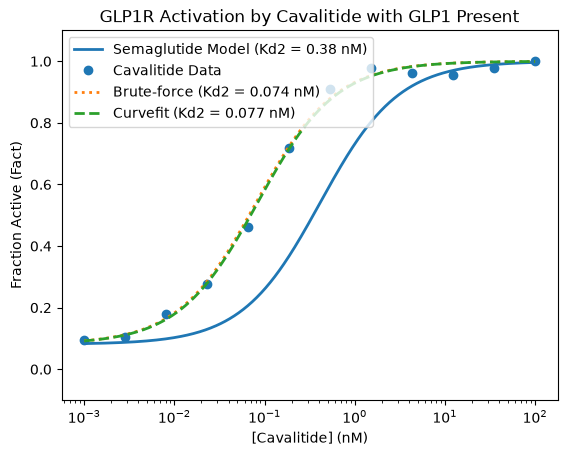

In [4]:
# fit_cavalitide_GLP1R.py

import numpy as np  #import numpy as np
import matplotlib.pyplot as plt #import matplotlib.pyplot as plt
from scipy.optimize import curve_fit #from scipy.optimize import curve_fit

def Fact(L1, L2, Kd1, Kd2): #def Fact(L1, L2, Kd1, Kd2):
    """Fractional Receptor Activation with Two Agonists L1 and L2""" 
    return (Kd2*L1+Kd1*L2) / (Kd1*Kd2 + Kd2*L1 + Kd1*L2) #return (Kd2*L1+Kd1*L2) / (Kd1*Kd2 + Kd2*L1 + Kd1*L2)

# Parameters [nM]
Kd1 = 0.17 # L1, GLP1
Kd2 = 0.38 # semaglutide Kd, for comparison (L2 = cavalitide is fitted below)
L1 = 0.015 # [nM] GLP1 (fasting)
L2 = np.logspace(-3, 2, 500) # [nM] semaglutide or cavalitide

# Load the data
data = np.loadtxt("cavalitide_data.csv", delimiter=",", skiprows=1) # define data variable by loading the CSV file
L2_loaded, Fact_loaded = data[:, 0], data[:, 1] # define L2_loaded and Fact_loaded variables from the data array

# Approach 1: Brute force optimization of Kd2: try many candidate values in a for loop
Kd2_candidates = np.logspace(-3, 2, 100) # [nM]
SSE_brute = np.inf # initialize SSE_brute to infinity
for Kd2_try in Kd2_candidates: # iterate through each candidate Kd2 value
    # Sum of squared errors between the data and the model for this candidate
    SSE = np.sum((Fact_loaded - Fact(L1, L2_loaded, Kd1, Kd2_try))**2) # calculate the sum of squared errors for this candidate
    if SSE < SSE_brute: # check if this candidate has a lower SSE than the current best
        SSE_brute = SSE # update the best SSE
        Kd2_brute = Kd2_try # update the best Kd2 candidate
print(f"Brute-force Kd2 = {Kd2_brute:.3f} nM (SSE = {SSE_brute:.4f})") # print the best brute-force Kd2 and its SSE

# Approach 2: Python curvefit of Kd2: related to steepest descent method
popt, pcov = curve_fit(lambda L2, Kd2: Fact(L1, L2, Kd1, Kd2), # define the curve fit function
                       L2_loaded, Fact_loaded, p0=[0.1], bounds=(0, np.inf)) # fit the curve to the data with initial guess and bounds
Kd2_fit = popt[0] # extract the fitted Kd2 value from the optimization results
SSE_fit = np.sum((Fact_loaded - Fact(L1, L2_loaded, Kd1, Kd2_fit))**2) # calculate the sum of squared errors for the fitted Kd2
print(f"Fitted Kd2 = {Kd2_fit:.3f} nM (SSE = {SSE_fit:.4f})") # print the fitted Kd2 and its SSE


plt.figure() # create a new figure for plotting
line, = plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2), lw=2, # plot the semaglutide model on a log scale
                     label=f"Semaglutide Model (Kd2 = {Kd2} nM)") # label the semaglutide model with its Kd2 value
plt.semilogx(L2_loaded, Fact_loaded, "o", c=line.get_color(), # plot the cavalitide data on a log scale
             label="Cavalitide Data") # label the cavalitide data
plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2_brute), ":", lw=2, # plot the brute-force model on a log scale
             label=f"Brute-force (Kd2 = {Kd2_brute:.3f} nM)") # label the brute-force model with its Kd2 value
plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2_fit), "--", lw=2, # plot the curvefit model on a log scale
             label=f"Curvefit (Kd2 = {Kd2_fit:.3f} nM)") # label the curvefit model with its Kd2 value

plt.ylim(-0.1, 1.1) # set the y-axis limits
plt.xlabel("[Cavalitide] (nM)") # set the x-axis label
plt.ylabel("Fraction Active (Fact)") # set the y-axis label
plt.title("GLP1R Activation by Cavalitide with GLP1 Present") # set the plot title
plt.legend(loc="upper left") # display the legend in the upper left corner
plt.show() # display the plot

## Task 2: Simulate the pharmacokinetics of Cavalitide treatment

TBD

## Task 3: Simulate a combined pharmacokinetics-pharmacokinetics (PKPD) model that predicts GLP1 receptor activity during treatment

TBD

## Conclusions:

Explain what your analyses suggest about the potential for Cavalitide in competition with semaglutide (oral or injected).

## Limitations and Future Work:

Describe the limitations of your project. If you had more time or additional data, explain how you would improve the analysis.

## AI Usage Statement:
*This is where you will provide a short description on whether AI (and which AI) was used for any of the sections above and whether it helped or why it did not help.*
- *Example statement: "We used Claude Code to generate our linear regression plot. At first, it did not include an R^2 calculation, so we added it to the code afterwards."*

## GitHub Repository Link:
*Please provide the link to your shared GitHub repository that includes this notebook and any other scripts, notebooks, or data that you used for this project.*


## References:
*You can use any format you like but provide the citations for facts that you referenced in this project notebook.*

## NOTES FROM YOUR TEAM: 
*This is where our team is taking notes and recording activity.*

## QUESTIONS FOR YOUR TA: 
*These are questions we have for our TA.*